# Antibacterial data analysis

In [1]:
from amp import load, work_in_outputs
work_in_outputs("05_antibacterial-activity")
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['svg.fonttype'] = 'none'

import numpy as np


In [2]:
# Import list of smiles
df = load("antibacterial_assays")
df.head()

,ID,Scaffold,DOI,Gram,Bacteria_Genus,Bacteria_Specie,Bacteria_Strain,Bacteria_FullName,Bacteria,Bioactive,...,Diameters of inhibition zones (mm),Amount/disk (µg),IC50 (µM),Growth treated bacteria,MIC,D/disk,logMIC,logDD,IC50,GTB
0,AQ001,anthraquinone,10.1016/j.fitote.2018.11.015,1,Staphylococcus,aureus,NaN,Staphylococcus aureus,Staphylococcus aureus,1,...,14.0,30.0,NaN,NaN,NaN,466.666667,NaN,2.669007,NaN,NaN
1,AQ002,anthraquinone,10.1016/j.fitote.2018.11.015,1,Staphylococcus,aureus,NaN,Staphylococcus aureus,Staphylococcus aureus,1,...,19.0,30.0,NaN,NaN,NaN,633.333333,NaN,2.801632,NaN,NaN
2,AQ003,anthraquinone,10.1007/s10600-020-03203-y,1,Bacillus,subtilis,NaN,Bacillus subtilis,Bacillus subtilis,0,...,NaN,NaN,NaN,NaN,>25,NaN,NaN,NaN,NaN,NaN
3,AQ003,anthraquinone,10.1007/s10600-020-03203-y,0,Escherichia,coli,NaN,Escherichia coli,Escherichia coli,0,...,NaN,NaN,NaN,NaN,>25,NaN,NaN,NaN,NaN,NaN
4,AQ003,anthraquinone,10.1007/s10600-020-03203-y,0,Pseudomonas,aeruginosa,NaN,Pseudomonas aeruginosa,Pseudomonas aeruginosa,0,...,NaN,NaN,NaN,NaN,>25,NaN,NaN,NaN,NaN,NaN


In [3]:
# fomatting Scaffolds series
df['Scaffold'] = [x.strip() for x in df['Scaffold']]
df['Scaffold'].unique()

df['Scaffold'] = df['Scaffold'].astype('category')

## Exploratory data analysis

### Assays per scaffold

In [4]:
df_grouped = df.groupby(by=['Scaffold','Bioactive']).count()
df_grouped

ID  DOI  Gram  Bacteria_Genus  Bacteria_Specie  \
Scaffold       Bioactive                                                    
anthraquinone  0          267  267   267             267              267   
               1          241  241   241             241              241   
benzophenone   0           28   28    28              28               28   
               1           38   38    38              38               38   
diphenyl-ether 0          243  243   243             243              243   
               1          172  172   172             172              172   
xanthone       0           35   35    35              35               35   
               1           57   57    57              57               57   

                          Bacteria_Strain  Bacteria_FullName  Bacteria  \
Scaffold       Bioactive                                                 
anthraquinone  0                      159                267       267   
               1                      179                241       241   
benzophenone   0                       18                 28        28   
               1                       29                 38        38   
diphenyl-ether 0                      159                243       243   
               1                       95                172       172   
xanthone       0                       18                 35        35   
               1                       26                 57        57   

                          MIC (μg/mL)  MIC (mg/L)  ...  \
Scaffold       Bioactive                           ...   
anthraquinone  0                   85           0  ...   
               1                   82           0  ...   
benzophenone   0                   28           0  ...   
               1                   38           0  ...   
diphenyl-ether 0                  146           9  ...   
               1                   79           8  ...   
xanthone       0                   23           0  ...   
               1                   31           0  ...   

                          Diameters of inhibition zones (mm)  \
Scaffold       Bioactive                                       
anthraquinone  0                                          49   
               1                                          49   
benzophenone   0                                           0   
               1                                           0   
diphenyl-ether 0                                          47   
               1                                          46   
xanthone       0                                           8   
               1                                           4   

                          Amount/disk (µg)  IC50 (µM)  \
Scaffold       Bioactive                                
anthraquinone  0                        44          0   
               1                        51          0   
benzophenone   0                         0          0   
               1                         0          0   
diphenyl-ether 0                        47         16   
               1                        46          8   
xanthone       0                         1          3   
               1                         4         18   

                          Growth treated bacteria  MIC  D/disk  logMIC  logDD  \
Scaffold       Bioactive                                                        
anthraquinone  0                                2  216      49       0      0   
               1                                2  190      49     189     49   
benzophenone   0                                0   28       0       0      0   
               1                                0   38       0      38      0   
diphenyl-ether 0                                0  179      47       0      1   
               1                                0  118      46     118     45   
xanthone       0                                0   24       8       0    

In [5]:
# Unstack dataframe
df_grouped_unstacked = df_grouped['ID'].unstack()
df_grouped_unstacked.columns = ['Not Active', 'Active']

In [6]:
print(df_grouped_unstacked['Active'] / df_grouped_unstacked.sum(axis=1),sep='t')

Scaffold
anthraquinone     0.474409
benzophenone      0.575758
diphenyl-ether    0.414458
xanthone          0.619565
dtype: float64


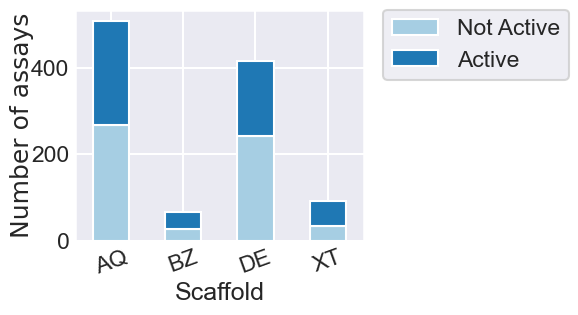

In [7]:
# plot 
sns.set_context("talk")
sns.set_style("darkgrid")
font = {'family': 'DejaVu Sans',
        'color':  '#262626',
        'weight': 'normal',
        }
colors = sns.color_palette("Paired")

f, ax = plt.subplots(figsize=(4, 3))
df_grouped_unstacked.plot(kind='bar', stacked=True,ax=ax, color=colors)

ax.set_box_aspect(0.8)
ax.tick_params(axis='both', which='major', pad=-5)

ax.set_xticklabels(['AQ','BZ','DE','XT'])
ax.set_ylabel("Number of assays", fontdict=font,labelpad=-2)
plt.xticks(rotation=20)
plt.legend(loc='upper right',bbox_to_anchor=(1.75,1.05))

plt.savefig('plots/bar_assays-scaffold.svg')

### Units

In [8]:
units= ['MIC (μg/mL)', 'MIC (μM)', 'Diameters of inhibition zones (mm)', 'IC50 (µM)']
df[units]

,MIC (μg/mL),MIC (μM),Diameters of inhibition zones (mm),IC50 (µM)
0,NaN,NaN,14.0,NaN
1,NaN,NaN,19.0,NaN
2,NaN,>25,NaN,NaN
3,NaN,>25,NaN,NaN
4,NaN,>25,NaN,NaN
...,...,...,...,...
1076,NaN,NaN,0.0,NaN
1077,NaN,NaN,0.0,NaN
1078,NaN,NaN,0.0,NaN
1079,NaN,NaN,0.0,NaN


In [9]:
# Dataframe with the total number of assays per unit
total_units = df[units].notna().sum()

In [10]:
# Dataframe wher NaN means not tested or > 100 and zero means tested but no value was reported
df_filtered = df[units].copy()

for column in units:
    df_filtered[column] = pd.to_numeric(df_filtered[column], errors='coerce') # replace non numeric values (ex: >100) by NaN

# Active compounds - values that are not NaN (ex: > 100) minus the values reported in the table as zero (zero means that the compound was tested but it was not active)
active_units = df_filtered.notna().sum() - df_filtered[df_filtered[units] == 0].count() 

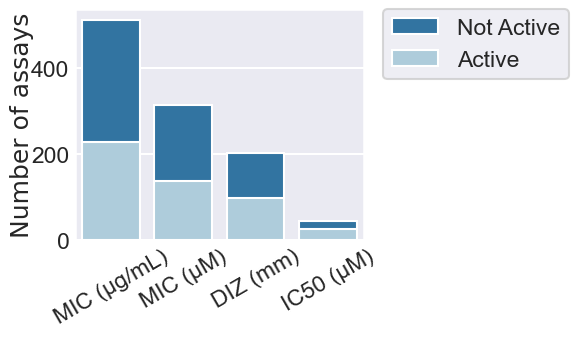

In [11]:
# plot 
sns.set_context("talk")
sns.set_style("darkgrid")
font = {'family': 'DejaVu Sans',
        'color':  '#262626',
        'weight': 'normal',
        }
colors = sns.color_palette("Paired")

f, ax = plt.subplots(figsize=(4, 3))
bar2 = sns.barplot(x= total_units.index, y=total_units, color=colors[1], label= 'Not Active')
bar1 = sns.barplot(x= active_units.index, y=active_units, color=colors[0],label= 'Active')


ax.set_box_aspect(0.8)
ax.tick_params(axis='both', which='major', pad=-5)

ax.set_xticklabels(['MIC (μg/mL)', 'MIC (μM)', 'DIZ (mm)', 'IC50 (µM)'])
ax.set_ylabel("Number of assays", fontdict=font,labelpad=-2)
plt.xticks(rotation=30)
plt.legend(loc='upper right',bbox_to_anchor=(1.75,1.05))
plt.savefig('plots/bar_assays-units.svg')

In [12]:
active_units

MIC (μg/mL)                           228
MIC (μM)                              137
Diameters of inhibition zones (mm)     99
IC50 (µM)                              26
dtype: int64

### Gram

In [13]:
# Gram classification of the bacteria agaisnt xanthone where assayed (1 as Gram+ and 0 as Gram-)
all_gram = df.Gram.value_counts()
print(all_gram)

1    724
0    357
Name: Gram, dtype: int64


In [14]:
# create a dic containing the major bacteria and the percentage of active compounds
gram_active = {all_gram.index[i]:pd.Series(df.loc[df.Gram == all_gram.index[i], 'Bioactive']).sum() for i in range(0,2) }
gram_active

gram_active = pd.Series(gram_active)
gram_active

1    360
0    148
dtype: int64

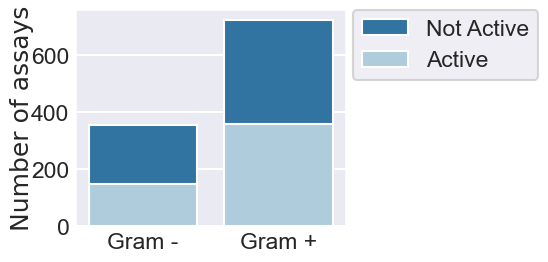

In [15]:
# Plot gram
sns.set_context("talk")
sns.set_style("darkgrid")
font = {'family': 'DejaVu Sans',
        'color':  '#262626',
        'weight': 'normal',
        }

colors = sns.color_palette("Paired")

f, ax = plt.subplots(figsize=(3.5, 3))
ax.set_box_aspect(0.8)

bar1 = sns.barplot(x=gram_active.index.values, y=all_gram, color=colors[1], label= 'Not Active')
bar2 = sns.barplot(x=gram_active.index.values, y=gram_active, color=colors[0], label= 'Active')

ax.set_xticklabels(['Gram -', 'Gram +'])
ax.set_ylabel("Number of assays", fontdict=font,labelpad=-2)

ax.tick_params(axis='both', which='major', pad=-5)
ax.set_xlabel(None)
plt.legend(loc='upper right',bbox_to_anchor=(1.75,1.05))

plt.savefig('plots/bar_assays-gram.svg')

In [16]:
# Percentage of active compounds
print({all_gram.index[i]:gram_active[i] / all_gram[i] for i in range(0,2)})


{1: 0.41456582633053224, 0: 0.4972375690607735}


### Bacteria assayed

In [17]:
# List the bacteria species that were evaluated
all = df.Bacteria.value_counts()
print(all)

Staphylococcus aureus             205
Bacillus subtilis                 169
Escherichia coli                  119
MRSA                               78
Pseudomonas aeruginosa             49
                                 ... 
Bacillus pumilus                    1
BCG                                 1
Bacillus mycoides                   1
Pseudomonas phaseolicola            1
Pseudoalteromonas nigrifaciens      1
Name: Bacteria, Length: 63, dtype: int64


In [18]:
print(pd.DataFrame.from_dict({all.index[i]:pd.Series(df.loc[df.Bacteria == all.index[i], 'Bioactive']).sum() / all[i] for i in range(0,7) }, orient='index', columns=['Perc']),sep='t')

                             Perc
Staphylococcus aureus    0.458537
Bacillus subtilis        0.550296
Escherichia coli         0.394958
MRSA                     0.602564
Pseudomonas aeruginosa   0.489796
Vibrio parahaemolyticus  0.326087
Enterococcus faecalis    0.405405


In [19]:
active = pd.DataFrame.from_dict({all.index[i]:pd.Series(df.loc[df.Bacteria == all.index[i], 'Bioactive']).sum() for i in range(0,8) }, orient='index', columns=['Count'])
active

,Count
Staphylococcus aureus,94
Bacillus subtilis,93
Escherichia coli,47
MRSA,47
Pseudomonas aeruginosa,24
Vibrio parahaemolyticus,15
Enterococcus faecalis,15
Bacillus cereus,14


In [20]:
# capture the first letter
active['first_letter'] = active.index.str[0]

# capture the second name
active['second_name'] = [active.index.str.rsplit(pat=' ',expand=True)[i][1] for i in range(0,len(active.index))]

# merge the letter and the name
active['name'] = active['first_letter'] + '. ' + active['second_name']

# Replace NaN by MRSA
active.loc[active['name'].isna(),'name'] = 'MRSA'

active

,Count,first_letter,second_name,name
Staphylococcus aureus,94,S,aureus,S. aureus
Bacillus subtilis,93,B,subtilis,B. subtilis
Escherichia coli,47,E,coli,E. coli
MRSA,47,M,NaN,MRSA
Pseudomonas aeruginosa,24,P,aeruginosa,P. aeruginosa
Vibrio parahaemolyticus,15,V,parahaemolyticus,V. parahaemolyticus
Enterococcus faecalis,15,E,faecalis,E. faecalis
Bacillus cereus,14,B,cereus,B. cereus


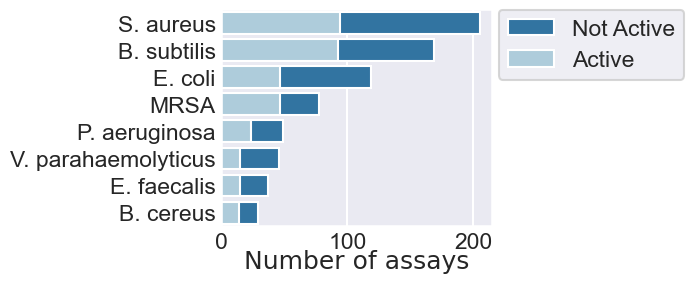

In [21]:
# Plot bacteria
sns.set_context("talk")
sns.set_style("darkgrid")
font = {'family': 'DejaVu Sans',
        'color':  '#262626',
        'weight': 'normal',
        }

f, ax = plt.subplots(figsize=(3.5, 3))
ax.set_box_aspect(0.8)

bar1 = sns.barplot(y=all.index[0:8], x=all[0:8], color=colors[1], label= 'Not Active')
bar2 = sns.barplot(y=active.index, x="Count", data=active, color=colors[0], label= 'Active')

ax.tick_params(axis='both', which='major', pad=-5)
ax.set_xlabel("Number of assays", fontdict=font,labelpad=-2)


ax.set_ylabel(None)
ax.set_yticklabels(active['name'])

plt.legend(loc='upper right',bbox_to_anchor=(1.75,1.05))

plt.savefig('plots/bar_assays-bacteria.svg')

### logMIC and logDD with Scaffolds

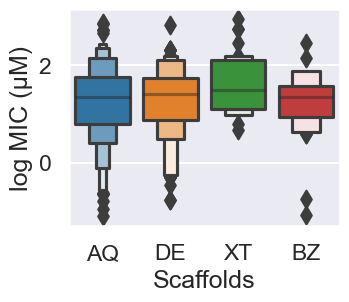

In [22]:
sns.set_context("talk")
sns.set_style("darkgrid")
font = {'family': 'DejaVu Sans',
        'color':  '#262626',
        'weight': 'normal',
        }

f, ax = plt.subplots(figsize=(3.5, 3))
ax.set_box_aspect(0.8)
g = sns.boxenplot(data=df, x='Scaffold',y='logMIC', order=['anthraquinone','diphenyl-ether', 'xanthone','benzophenone'])
g.set_xticklabels(['AQ','DE','XT','BZ'])
g.set_xlabel('Scaffolds')
g.set_ylabel('log MIC (µM)')
plt.savefig('plots/boxen_logMIC-scaffold.svg')

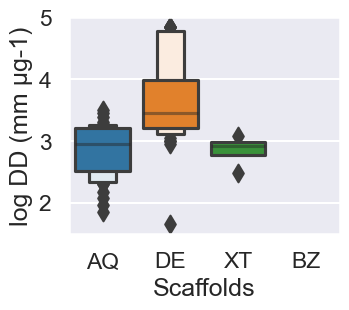

In [23]:
f, ax = plt.subplots(figsize=(3.5, 3))
ax.set_box_aspect(0.8)
g = sns.boxenplot(data=df, x='Scaffold',y='logDD', order=['anthraquinone','diphenyl-ether', 'xanthone','benzophenone'])
g.set_xticklabels(['AQ','DE','XT','BZ'])
g.set_xlabel('Scaffolds')
g.set_ylabel('log DD (mm µg-1)')
plt.savefig('plots/boxen_logDD-scaffold.svg')

### MIC and DD with clusters

#### Evaluate butina targeted for few clusters

In [24]:
# read DataFrame with clusters
df_clusters = load("clusters_cutoff_0_66")

# Merge with current dataframe
df_clustered = pd.merge(left=df,right=df_clusters)

In [25]:
df_clustered['cluster'].value_counts()

cluster1     302
cluster3     218
cluster2     177
misc         107
cluster5      64
cluster6      63
cluster4      46
cluster7      31
cluster8      30
cluster11     22
cluster10     22
cluster9      20
Name: cluster, dtype: int64

Text(0, 0.5, 'log MIC (µM)')

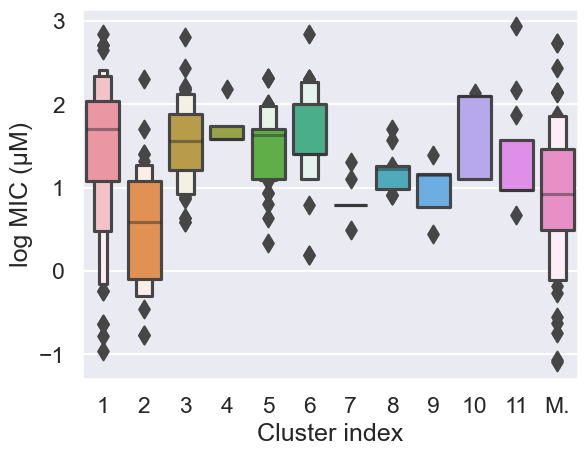

In [26]:
clusters = ['cluster1', 'cluster2', 'cluster3', 'cluster4', 'cluster5', 'cluster6', 'cluster7','cluster8','cluster9','cluster10', 'cluster11','misc']

g = sns.boxenplot(data=df_clustered, x='cluster',y='logMIC', order=clusters)
g.set_xticklabels(['1','2','3','4','5','6','7','8','9','10','11','M.'])
g.set_xlabel('Cluster index')
g.set_ylabel('log MIC (µM)')

#### Evaluate butina targeted for homogeneous clusters

In [27]:
# read DataFrame with clusters
df_clusters = load("clusters_cutoff_0_5")

# Merge with current dataframe
df_clustered = pd.merge(left=df,right=df_clusters)

In [28]:
df_clustered['cluster'].value_counts()

misc         276
cluster2     118
cluster5      91
cluster3      87
cluster1      82
cluster4      51
cluster6      49
cluster7      39
cluster11     32
cluster16     31
cluster14     29
cluster10     29
cluster15     26
cluster8      25
cluster18     24
cluster9      24
cluster12     21
cluster17     16
cluster13     16
cluster19     15
Name: cluster, dtype: int64

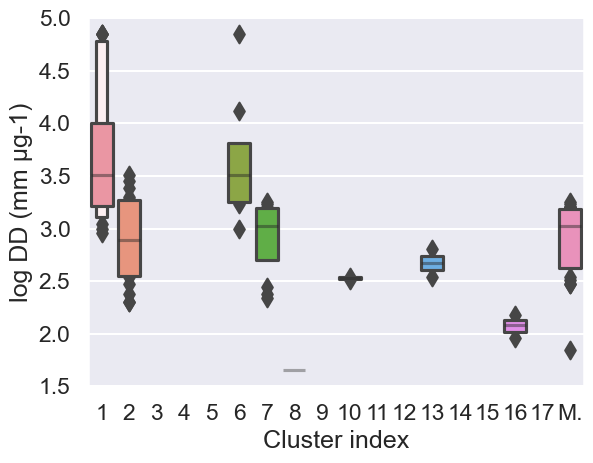

In [29]:
clusters = ['cluster1', 'cluster2', 'cluster3', 'cluster4', 'cluster5', 'cluster6', 'cluster7','cluster8','cluster9','cluster10', 'cluster11','cluster12','cluster13','cluster14','cluster15','cluster16','cluster17','misc']

g = sns.boxenplot(data=df_clustered, x='cluster',y='logDD', order=clusters)
g.set_xticklabels(['1','2','3','4','5','6','7','8','9','10','11','12','13','14','15','16','17','M.'])
g.set_xlabel('Cluster index')
g.set_ylabel('log DD (mm µg-1)')
plt.savefig('plots/boxen_logDD-clusters.svg')

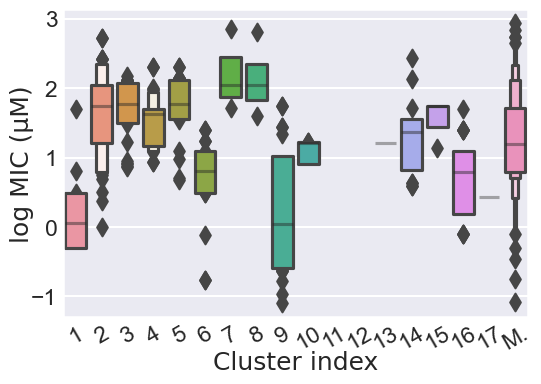

In [30]:
clusters = ['cluster1', 'cluster2', 'cluster3', 'cluster4', 'cluster5', 'cluster6', 'cluster7','cluster8','cluster9','cluster10', 'cluster11','cluster12','cluster13','cluster14','cluster15','cluster16','cluster17','misc']

f, ax = plt.subplots(figsize=(6, 4))
g = sns.boxenplot(data=df_clustered, x='cluster',y='logMIC', order=clusters)
g.set_xticklabels(['1','2','3','4','5','6','7','8','9','10','11','12','13','14','15','16','17','M.'])
ax.tick_params(axis='both', which='major', pad=-5)
g.set_xlabel('Cluster index',fontdict=font,labelpad=-2)
g.set_ylabel('log MIC (µM)',fontdict=font,labelpad=-2)
plt.xticks(rotation = 30)
plt.savefig('plots/boxen_logMIC-clusters.svg')